In [1]:
##Plotting for the three case studies 

In [110]:
from climada_petals.hazard import TCForecast
import logging
import datetime
import os
import numpy as np
import geopandas as gpd

In [111]:
###SUBNATIONAL DIVISION 
import geopandas as gpd
geofile_MOZ = '/cluster/work/climate/gespejo/data/infrastructure/Mozambique_results_MOZ/gadm41_MOZ_shp/gadm41_MOZ_1.shp'
gadm_MOZ = gpd.read_file(geofile_MOZ)

In [112]:
### CREATE POINTS FOR EVERY CI AND PEOPLE 
from climada_petals.hazard.IMP_TRACKFORECAST import convert_to_geodf
gadm_MOZ_gdf = convert_to_geodf(gadm_MOZ, ['NAME_1', 'geometry'])

In [113]:
import pickle

In [114]:
with open('/cluster/work/climate/gespejo/IDAI_picklefiles_cat/timpacts_all.pkl', 'rb') as file:
    timpacts_all_IDAI_cat = pickle.load(file)
with open('/cluster/work/climate/gespejo/KENNETH_picklefiles_cat/timpacts_all.pkl', 'rb') as file:
    timpacts_all_KENNETH_cat = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles_cat/timpacts_all.pkl', 'rb') as file:
    timpacts_all_FREDDY_cat = pickle.load(file)
with open('/cluster/work/climate/gespejo/IDAI_picklefiles/timpacts_all.pkl', 'rb') as file:
    timpacts_all_IDAI_struc = pickle.load(file)
with open('/cluster/work/climate/gespejo/KENNETH_picklefiles/timpacts_all.pkl', 'rb') as file:
    timpacts_all_KENNETH_struc = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/timpacts_all.pkl', 'rb') as file:
    timpacts_all_FREDDY_struc = pickle.load(file)

In [115]:
['imph1_MOZ_Idai_20190310120000']

['imph1_MOZ_Idai_20190310120000']

In [116]:
timpacts_all_IDAI_cat_imph1 =  timpacts_all_IDAI_cat ['imph1'] 

In [117]:
###plotting total impact of those three case studies 

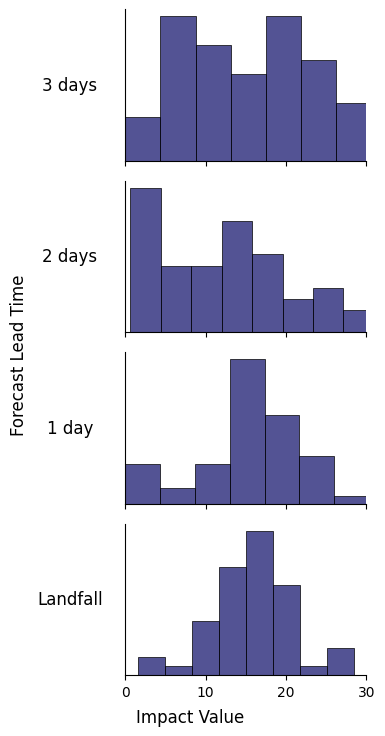

In [118]:
import seaborn as sns
import matplotlib.pyplot as plt

# Extract the last 4 keys from the dictionary
impact_keys = list(timpacts_all_IDAI_cat['imph1'].keys())[-4:]
num_plots = len(impact_keys)

# Custom labels for the y-axis (corresponding to each plot)
y_labels = ['3 days', '2 days', '1 day', 'Landfall']

# Define the midnightblue color for the histograms
dark_blue = "midnightblue"

# Adjust width and reduce height for narrower plots
fig, axes = plt.subplots(num_plots, 1, figsize=(4, 2 * num_plots), sharex=True)

# Ensure axes is iterable even if there's only one key
if num_plots == 1:
    axes = [axes]

# Iterate over the last 4 keys and plot each histogram in a new subplot
for i, key in enumerate(impact_keys):
    sns.histplot(
        timpacts_all_IDAI_cat['imph1'][key],
        bins=8,
        kde=False,                # Removed KDE curve
        color=dark_blue,          # Apply midnightblue color
        stat='density',
        edgecolor='black',
        linewidth=0.5,
        element='bars',
        ax=axes[i]                # Plot in the corresponding subplot
    )

    # Set a smaller x-axis range (adjust values as needed)
    axes[i].set_xlim(0, 30)       

    # Set custom y-axis label (e.g., "3 days", "2 days", etc.)
    axes[i].set_ylabel(y_labels[i], fontsize=12, rotation=0, labelpad=40, va='center')

    # Remove y-axis ticks for a cleaner look
    axes[i].tick_params(axis='y', which='both', left=False, labelleft=False)

    # Only show left and bottom spines (x and y axes)
    axes[i].spines['left'].set_visible(True)
    axes[i].spines['bottom'].set_visible(True)
    axes[i].spines['top'].set_visible(False)
    axes[i].spines['right'].set_visible(False)

# Set common x-axis label at the bottom
fig.text(0.5, 0.04, 'Impact Value', ha='center', fontsize=12)
fig.text(0.05, 0.5, 'Forecast Lead Time', va='center', rotation='vertical', fontsize=12)

# Adjust layout for a neat appearance
plt.tight_layout(rect=[0.08, 0.05, 1, 0.95])

# Save the figure to the specified path
save_path = '/cluster/home/gespejo/totalimpacts_TC_paper/IDAI_cat1_totalimpact.jpg'
plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')  # High resolution (300 dpi)

# Show the plot
plt.show()

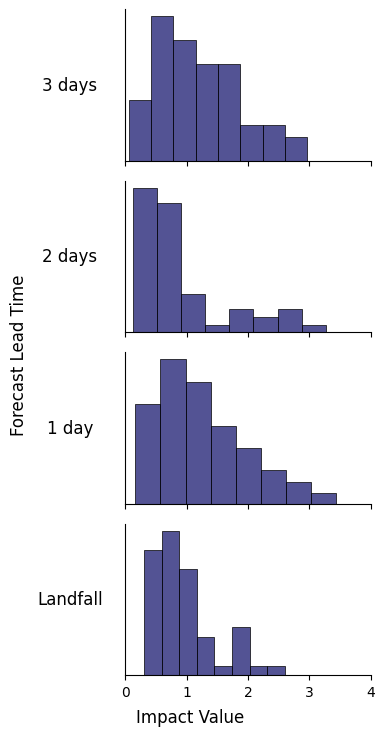

In [122]:
## structural function Eberenz 
import seaborn as sns
import matplotlib.pyplot as plt

# Extract the last 4 keys from the dictionary
impact_keys = list(timpacts_all_IDAI_struc['imph1'].keys())[-4:]
num_plots = len(impact_keys)

# Custom labels for the y-axis (corresponding to each plot)
y_labels = ['3 days', '2 days', '1 day', 'Landfall']

# Define the midnightblue color for the histograms
dark_blue = "midnightblue"

# Adjust width and reduce height for narrower plots
fig, axes = plt.subplots(num_plots, 1, figsize=(4, 2 * num_plots), sharex=True)

# Ensure axes is iterable even if there's only one key
if num_plots == 1:
    axes = [axes]

# Iterate over the last 4 keys and plot each histogram in a new subplot
for i, key in enumerate(impact_keys):
    sns.histplot(
        timpacts_all_IDAI_struc['imph1'][key],
        bins=8,
        kde=False,                # Removed KDE curve
        color=dark_blue,          # Apply midnightblue color
        stat='density',
        edgecolor='black',
        linewidth=0.5,
        element='bars',
        ax=axes[i]                # Plot in the corresponding subplot
    )

    # Set a smaller x-axis range (adjust values as needed)
    axes[i].set_xlim(0, 4)       

    # Set custom y-axis label (e.g., "3 days", "2 days", etc.)
    axes[i].set_ylabel(y_labels[i], fontsize=12, rotation=0, labelpad=40, va='center')

    # Remove y-axis ticks for a cleaner look
    axes[i].tick_params(axis='y', which='both', left=False, labelleft=False)

    # Only show left and bottom spines (x and y axes)
    axes[i].spines['left'].set_visible(True)
    axes[i].spines['bottom'].set_visible(True)
    axes[i].spines['top'].set_visible(False)
    axes[i].spines['right'].set_visible(False)

# Set common x-axis label at the bottom
fig.text(0.5, 0.04, 'Impact Value', ha='center', fontsize=12)
fig.text(0.05, 0.5, 'Forecast Lead Time', va='center', rotation='vertical', fontsize=12)

# Adjust layout for a neat appearance
plt.tight_layout(rect=[0.08, 0.05, 1, 0.95])

# Save the figure to the specified path
save_path = '/cluster/home/gespejo/totalimpacts_TC_paper/IDAI_Eberenz_totalimpact.jpg'
plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')  # High resolution (300 dpi)

# Show the plot
plt.show()

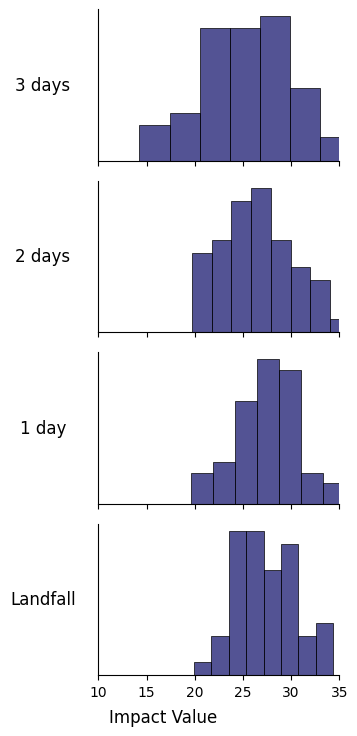

In [123]:
## structural function Eberenz 
import seaborn as sns
import matplotlib.pyplot as plt

# Extract the last 4 keys from the dictionary
impact_keys = list(timpacts_all_IDAI_struc['imph2'].keys())[-4:]
num_plots = len(impact_keys)

# Custom labels for the y-axis (corresponding to each plot)
y_labels = ['3 days', '2 days', '1 day', 'Landfall']

# Define the midnightblue color for the histograms
dark_blue = "midnightblue"

# Adjust width and reduce height for narrower plots
fig, axes = plt.subplots(num_plots, 1, figsize=(4, 2 * num_plots), sharex=True)

# Ensure axes is iterable even if there's only one key
if num_plots == 1:
    axes = [axes]

# Iterate over the last 4 keys and plot each histogram in a new subplot
for i, key in enumerate(impact_keys):
    sns.histplot(
        timpacts_all_IDAI_struc['imph2'][key],
        bins=8,
        kde=False,                # Removed KDE curve
        color=dark_blue,          # Apply midnightblue color
        stat='density',
        edgecolor='black',
        linewidth=0.5,
        element='bars',
        ax=axes[i]                # Plot in the corresponding subplot
    )

    # Set a smaller x-axis range (adjust values as needed)
    axes[i].set_xlim(10, 35)       

    # Set custom y-axis label (e.g., "3 days", "2 days", etc.)
    axes[i].set_ylabel(y_labels[i], fontsize=12, rotation=0, labelpad=40, va='center')

    # Remove y-axis ticks for a cleaner look
    axes[i].tick_params(axis='y', which='both', left=False, labelleft=False)

    # Only show left and bottom spines (x and y axes)
    axes[i].spines['left'].set_visible(True)
    axes[i].spines['bottom'].set_visible(True)
    axes[i].spines['top'].set_visible(False)
    axes[i].spines['right'].set_visible(False)

# Set common x-axis label at the bottom
fig.text(0.5, 0.04, 'Impact Value', ha='center', fontsize=12)
#fig.text(0.05, 0.5, 'Forecast Lead Time', va='center', rotation='vertical', fontsize=12)

# Adjust layout for a neat appearance
plt.tight_layout(rect=[0.08, 0.05, 1, 0.95])

# Save the figure to the specified path
save_path = '/cluster/home/gespejo/totalimpacts_TC_paper/IDAI_Deltares_totalimpact.jpg'
plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')  # High resolution (300 dpi)

# Show the plot
plt.show()

In [ ]:
### KENNETH 

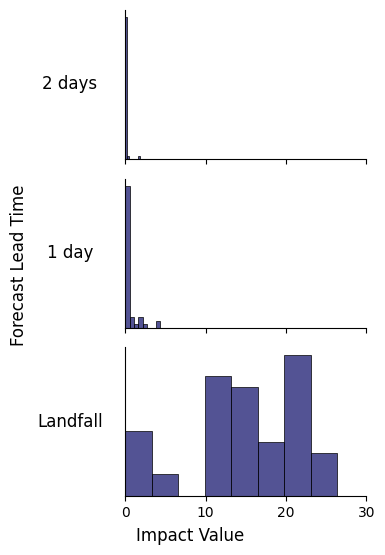

In [124]:
import seaborn as sns
import matplotlib.pyplot as plt

# Extract the last 4 keys from the dictionary
impact_keys = list(timpacts_all_KENNETH_cat['imph1'].keys())[-4:]
num_plots = len(impact_keys)

# Custom labels for the y-axis (corresponding to each plot)
y_labels = [ '2 days', '1 day', 'Landfall']

# Define the midnightblue color for the histograms
dark_blue = "midnightblue"

# Adjust width and reduce height for narrower plots
fig, axes = plt.subplots(num_plots, 1, figsize=(4, 2 * num_plots), sharex=True)

# Ensure axes is iterable even if there's only one key
if num_plots == 1:
    axes = [axes]

# Iterate over the last 4 keys and plot each histogram in a new subplot
for i, key in enumerate(impact_keys):
    sns.histplot(
        timpacts_all_KENNETH_cat['imph1'][key],
        bins=8,
        kde=False,                # Removed KDE curve
        color=dark_blue,          # Apply midnightblue color
        stat='density',
        edgecolor='black',
        linewidth=0.5,
        element='bars',
        ax=axes[i]                # Plot in the corresponding subplot
    )

    # Set a smaller x-axis range (adjust values as needed)
    axes[i].set_xlim(0, 30)       

    # Set custom y-axis label (e.g., "3 days", "2 days", etc.)
    axes[i].set_ylabel(y_labels[i], fontsize=12, rotation=0, labelpad=40, va='center')

    # Remove y-axis ticks for a cleaner look
    axes[i].tick_params(axis='y', which='both', left=False, labelleft=False)

    # Only show left and bottom spines (x and y axes)
    axes[i].spines['left'].set_visible(True)
    axes[i].spines['bottom'].set_visible(True)
    axes[i].spines['top'].set_visible(False)
    axes[i].spines['right'].set_visible(False)

# Set common x-axis label at the bottom
fig.text(0.5, 0.04, 'Impact Value', ha='center', fontsize=12)
fig.text(0.05, 0.5, 'Forecast Lead Time', va='center', rotation='vertical', fontsize=12)

# Adjust layout for a neat appearance
plt.tight_layout(rect=[0.08, 0.05, 1, 0.95])

# Save the figure to the specified path
save_path = '/cluster/home/gespejo/totalimpacts_TC_paper/KENNETH_cat1_totalimpact.jpg'
plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')  # High resolution (300 dpi)

# Show the plot
plt.show()

import seaborn as sns
import matplotlib.pyplot as plt

# Extract the last 4 keys from the dictionary
impact_keys = list(timpacts_all_KENNETH_cat['imph1'].keys())[-4:]
num_plots = len(impact_keys)

# Custom labels for the y-axis (corresponding to each plot)
y_labels = ['2 days', '1 day', 'Landfall']

# Define the midnightblue color for the histograms
dark_blue = "midnightblue"

# Adjust width and reduce height for narrower plots
fig, axes = plt.subplots(num_plots, 1, figsize=(5, 2 * num_plots), sharex=False)  # sharex=False for individual scaling

# Ensure axes is iterable even if there's only one key
if num_plots == 1:
    axes = [axes]

# Iterate over the last 4 keys and plot each histogram in a new subplot
for i, key in enumerate(impact_keys):
    data = timpacts_all_KENNETH_cat['imph1'][key]

    sns.histplot(
        data,
        bins=10,                  # Increased bins for better detail in low-impact ranges
        kde=False,
        color=dark_blue,
        stat='density',
        edgecolor='black',
        linewidth=0.5,
        element='bars',
        ax=axes[i]
    )

    #  Custom x-axis range for the first two plots
    if i == 0:  # 2 days
        axes[i].set_xlim(0, 2)
    elif i == 1:  # 1 day
        axes[i].set_xlim(0, 5)
    else:  # Landfall - dynamic scaling
        max_val = max(data) + 2  # Slightly higher than max for better spacing
        axes[i].set_xlim(0, max_val)

    # Set custom y-axis label (e.g., "2 days", "1 day", etc.)
    axes[i].set_ylabel(y_labels[i], fontsize=12, rotation=0, labelpad=40, va='center')

    # Remove y-axis ticks for a cleaner look
    axes[i].tick_params(axis='y', which='both', left=False, labelleft=False)

    # Only show left and bottom spines (x and y axes)
    axes[i].spines['left'].set_visible(True)
    axes[i].spines['bottom'].set_visible(True)
    axes[i].spines['top'].set_visible(False)
    axes[i].spines['right'].set_visible(False)

# Set common x-axis label at the bottom
fig.text(0.5, 0.04, 'Impact Value', ha='center', fontsize=12)
fig.text(0.05, 0.5, 'Forecast Lead Time', va='center', rotation='vertical', fontsize=12)

# Adjust layout for a neat appearance
plt.tight_layout(rect=[0.08, 0.05, 1, 0.95])

# Save the figure to the specified path
save_path = '/cluster/home/gespejo/totalimpacts_TC_paper/KENNETH_cat1_totalimpact.jpg'
plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')

# Show the plot
plt.show()

#print(f"Plot saved successfully at: {save_path}")

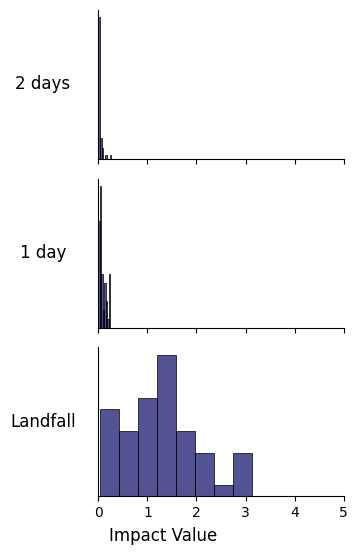

In [125]:
## structural function Eberenz 
import seaborn as sns
import matplotlib.pyplot as plt

# Extract the last 4 keys from the dictionary
impact_keys = list(timpacts_all_KENNETH_struc['imph1'].keys())[-4:]
num_plots = len(impact_keys)

# Custom labels for the y-axis (corresponding to each plot)
y_labels = ['2 days', '1 day', 'Landfall']

# Define the midnightblue color for the histograms
dark_blue = "midnightblue"

# Adjust width and reduce height for narrower plots
fig, axes = plt.subplots(num_plots, 1, figsize=(4, 2 * num_plots), sharex=True)

# Ensure axes is iterable even if there's only one key
if num_plots == 1:
    axes = [axes]

# Iterate over the last 4 keys and plot each histogram in a new subplot
for i, key in enumerate(impact_keys):
    sns.histplot(
        timpacts_all_KENNETH_struc['imph1'][key],
        bins=8,
        kde=False,                # Removed KDE curve
        color=dark_blue,          # Apply midnightblue color
        stat='density',
        edgecolor='black',
        linewidth=0.5,
        element='bars',
        ax=axes[i]                # Plot in the corresponding subplot
    )

    # Set a smaller x-axis range (adjust values as needed)
    axes[i].set_xlim(0, 5)       

    # Set custom y-axis label (e.g., "3 days", "2 days", etc.)
    axes[i].set_ylabel(y_labels[i], fontsize=12, rotation=0, labelpad=40, va='center')

    # Remove y-axis ticks for a cleaner look
    axes[i].tick_params(axis='y', which='both', left=False, labelleft=False)

    # Only show left and bottom spines (x and y axes)
    axes[i].spines['left'].set_visible(True)
    axes[i].spines['bottom'].set_visible(True)
    axes[i].spines['top'].set_visible(False)
    axes[i].spines['right'].set_visible(False)

# Set common x-axis label at the bottom
fig.text(0.5, 0.04, 'Impact Value', ha='center', fontsize=12)
#fig.text(0.05, 0.5, 'Forecast Lead Time', va='center', rotation='vertical', fontsize=12)

# Adjust layout for a neat appearance
plt.tight_layout(rect=[0.08, 0.05, 1, 0.95])

# Save the figure to the specified path
save_path = '/cluster/home/gespejo/totalimpacts_TC_paper/KENNETH_Eberenz_totalimpact.jpg'
plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')  # High resolution (300 dpi)

# Show the plot
plt.show()

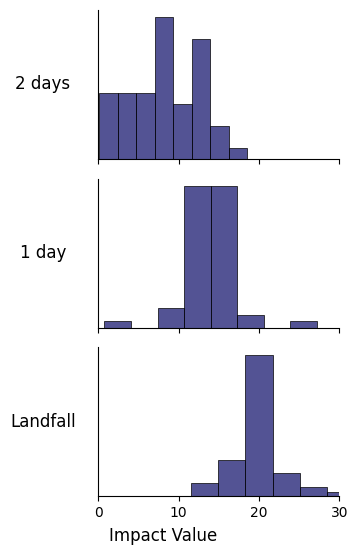

In [126]:
## structural function Deltares 
import seaborn as sns
import matplotlib.pyplot as plt

# Extract the last 4 keys from the dictionary
impact_keys = list(timpacts_all_KENNETH_struc['imph2'].keys())[-4:]
num_plots = len(impact_keys)

# Custom labels for the y-axis (corresponding to each plot)
y_labels = ['2 days', '1 day', 'Landfall']

# Define the midnightblue color for the histograms
dark_blue = "midnightblue"

# Adjust width and reduce height for narrower plots
fig, axes = plt.subplots(num_plots, 1, figsize=(4, 2 * num_plots), sharex=True)

# Ensure axes is iterable even if there's only one key
if num_plots == 1:
    axes = [axes]

# Iterate over the last 4 keys and plot each histogram in a new subplot
for i, key in enumerate(impact_keys):
    sns.histplot(
        timpacts_all_KENNETH_struc['imph2'][key],
        bins=8,
        kde=False,                # Removed KDE curve
        color=dark_blue,          # Apply midnightblue color
        stat='density',
        edgecolor='black',
        linewidth=0.5,
        element='bars',
        ax=axes[i]                # Plot in the corresponding subplot
    )

    # Set a smaller x-axis range (adjust values as needed)
    axes[i].set_xlim(0, 30)       

    # Set custom y-axis label (e.g., "3 days", "2 days", etc.)
    axes[i].set_ylabel(y_labels[i], fontsize=12, rotation=0, labelpad=40, va='center')

    # Remove y-axis ticks for a cleaner look
    axes[i].tick_params(axis='y', which='both', left=False, labelleft=False)

    # Only show left and bottom spines (x and y axes)
    axes[i].spines['left'].set_visible(True)
    axes[i].spines['bottom'].set_visible(True)
    axes[i].spines['top'].set_visible(False)
    axes[i].spines['right'].set_visible(False)

# Set common x-axis label at the bottom
fig.text(0.5, 0.04, 'Impact Value', ha='center', fontsize=12)
#fig.text(0.05, 0.5, 'Forecast Lead Time', va='center', rotation='vertical', fontsize=12)

# Adjust layout for a neat appearance
plt.tight_layout(rect=[0.08, 0.05, 1, 0.95])

# Save the figure to the specified path
save_path = '/cluster/home/gespejo/totalimpacts_TC_paper/KENNETH_Deltares_totalimpact.jpg'
plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')  # High resolution (300 dpi)

# Show the plot
plt.show()

In [ ]:
## FREDDY 

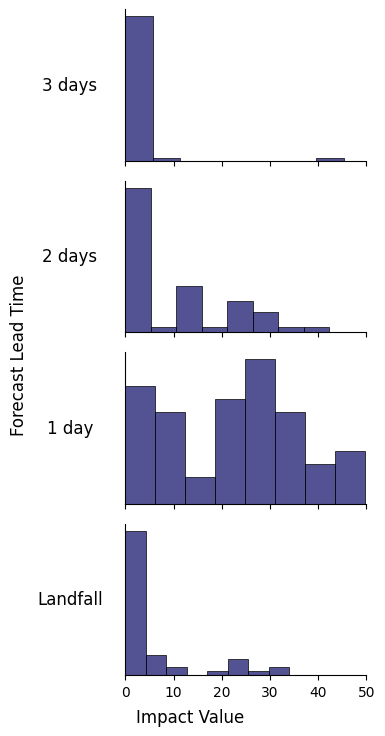

In [129]:
import seaborn as sns
import matplotlib.pyplot as plt

# Extract the last 4 keys from the dictionary
impact_keys = list(timpacts_all_FREDDY_cat['imph1'].keys())[-4:]
num_plots = len(impact_keys)

# Custom labels for the y-axis (corresponding to each plot)
y_labels = ['3 days' ,'2 days', '1 day', 'Landfall']

# Define the midnightblue color for the histograms
dark_blue = "midnightblue"

# Adjust width and reduce height for narrower plots
fig, axes = plt.subplots(num_plots, 1, figsize=(4, 2 * num_plots), sharex=True)

# Ensure axes is iterable even if there's only one key
if num_plots == 1:
    axes = [axes]

# Iterate over the last 4 keys and plot each histogram in a new subplot
for i, key in enumerate(impact_keys):
    sns.histplot(
        timpacts_all_FREDDY_cat['imph1'][key],
        bins=8,
        kde=False,                # Removed KDE curve
        color=dark_blue,          # Apply midnightblue color
        stat='density',
        edgecolor='black',
        linewidth=0.5,
        element='bars',
        ax=axes[i]                # Plot in the corresponding subplot
    )

    # Set a smaller x-axis range (adjust values as needed)
    axes[i].set_xlim(0, 50)       

    # Set custom y-axis label (e.g., "3 days", "2 days", etc.)
    axes[i].set_ylabel(y_labels[i], fontsize=12, rotation=0, labelpad=40, va='center')

    # Remove y-axis ticks for a cleaner look
    axes[i].tick_params(axis='y', which='both', left=False, labelleft=False)

    # Only show left and bottom spines (x and y axes)
    axes[i].spines['left'].set_visible(True)
    axes[i].spines['bottom'].set_visible(True)
    axes[i].spines['top'].set_visible(False)
    axes[i].spines['right'].set_visible(False)

# Set common x-axis label at the bottom
fig.text(0.5, 0.04, 'Impact Value', ha='center', fontsize=12)
fig.text(0.05, 0.5, 'Forecast Lead Time', va='center', rotation='vertical', fontsize=12)

# Adjust layout for a neat appearance
plt.tight_layout(rect=[0.08, 0.05, 1, 0.95])

# Save the figure to the specified path
save_path = '/cluster/home/gespejo/totalimpacts_TC_paper/FREDDY_cat1_totalimpact.jpg'
plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')  # High resolution (300 dpi)

# Show the plot
plt.show()

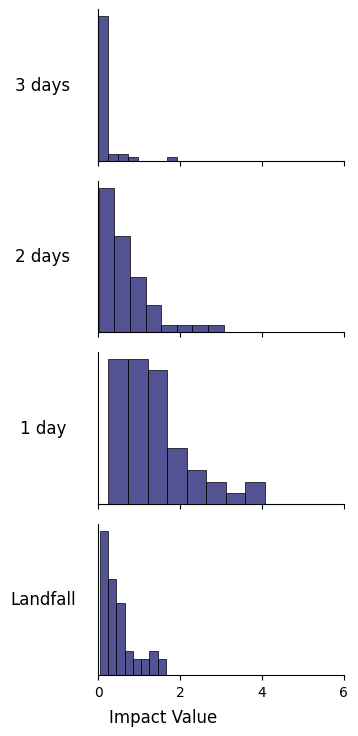

In [104]:
## structural function Eberenz 
import seaborn as sns
import matplotlib.pyplot as plt

# Extract the last 4 keys from the dictionary
impact_keys = list(timpacts_all_FREDDY_struc['imph1'].keys())[-4:]
num_plots = len(impact_keys)

# Custom labels for the y-axis (corresponding to each plot)
y_labels = ['3 days','2 days', '1 day', 'Landfall']

# Define the midnightblue color for the histograms
dark_blue = "midnightblue"

# Adjust width and reduce height for narrower plots
fig, axes = plt.subplots(num_plots, 1, figsize=(4, 2 * num_plots), sharex=True)

# Ensure axes is iterable even if there's only one key
if num_plots == 1:
    axes = [axes]

# Iterate over the last 4 keys and plot each histogram in a new subplot
for i, key in enumerate(impact_keys):
    sns.histplot(
        timpacts_all_FREDDY_struc['imph1'][key],
        bins=8,
        kde=False,                # Removed KDE curve
        color=dark_blue,          # Apply midnightblue color
        stat='density',
        edgecolor='black',
        linewidth=0.5,
        element='bars',
        ax=axes[i]                # Plot in the corresponding subplot
    )

    # Set a smaller x-axis range (adjust values as needed)
    axes[i].set_xlim(0, 6)       

    # Set custom y-axis label (e.g., "3 days", "2 days", etc.)
    axes[i].set_ylabel(y_labels[i], fontsize=12, rotation=0, labelpad=40, va='center')

    # Remove y-axis ticks for a cleaner look
    axes[i].tick_params(axis='y', which='both', left=False, labelleft=False)

    # Only show left and bottom spines (x and y axes)
    axes[i].spines['left'].set_visible(True)
    axes[i].spines['bottom'].set_visible(True)
    axes[i].spines['top'].set_visible(False)
    axes[i].spines['right'].set_visible(False)

# Set common x-axis label at the bottom
fig.text(0.5, 0.04, 'Impact Value', ha='center', fontsize=12)
#fig.text(0.05, 0.5, 'Forecast Lead Time', va='center', rotation='vertical', fontsize=12)

# Adjust layout for a neat appearance
plt.tight_layout(rect=[0.08, 0.05, 1, 0.95])

# Save the figure to the specified path
save_path = '/cluster/home/gespejo/totalimpacts_TC_paper/FREDDY_Eberenz_totalimpact.jpg'
plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')  # High resolution (300 dpi)

# Show the plot
plt.show()

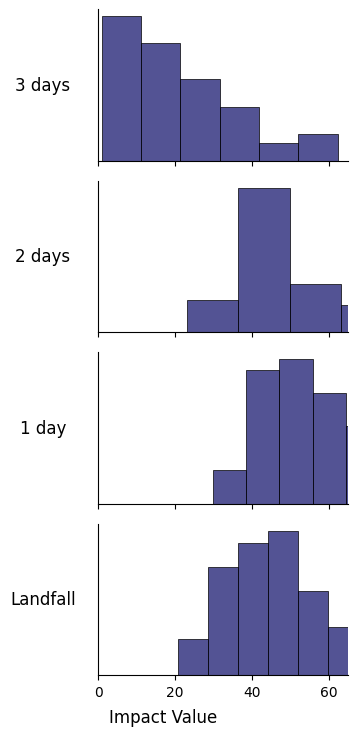

In [130]:
## structural function Deltares 
import seaborn as sns
import matplotlib.pyplot as plt

# Extract the last 4 keys from the dictionary
impact_keys = list(timpacts_all_FREDDY_struc['imph2'].keys())[-4:]
num_plots = len(impact_keys)

# Custom labels for the y-axis (corresponding to each plot)
y_labels = ['3 days','2 days', '1 day', 'Landfall']

# Define the midnightblue color for the histograms
dark_blue = "midnightblue"

# Adjust width and reduce height for narrower plots
fig, axes = plt.subplots(num_plots, 1, figsize=(4, 2 * num_plots), sharex=True)

# Ensure axes is iterable even if there's only one key
if num_plots == 1:
    axes = [axes]

# Iterate over the last 4 keys and plot each histogram in a new subplot
for i, key in enumerate(impact_keys):
    sns.histplot(
        timpacts_all_FREDDY_struc['imph2'][key],
        bins=8,
        kde=False,                # Removed KDE curve
        color=dark_blue,          # Apply midnightblue color
        stat='density',
        edgecolor='black',
        linewidth=0.5,
        element='bars',
        ax=axes[i]                # Plot in the corresponding subplot
    )

    # Set a smaller x-axis range (adjust values as needed)
    axes[i].set_xlim(0, 65)       

    # Set custom y-axis label (e.g., "3 days", "2 days", etc.)
    axes[i].set_ylabel(y_labels[i], fontsize=12, rotation=0, labelpad=40, va='center')

    # Remove y-axis ticks for a cleaner look
    axes[i].tick_params(axis='y', which='both', left=False, labelleft=False)

    # Only show left and bottom spines (x and y axes)
    axes[i].spines['left'].set_visible(True)
    axes[i].spines['bottom'].set_visible(True)
    axes[i].spines['top'].set_visible(False)
    axes[i].spines['right'].set_visible(False)

# Set common x-axis label at the bottom
fig.text(0.5, 0.04, 'Impact Value', ha='center', fontsize=12)
#fig.text(0.05, 0.5, 'Forecast Lead Time', va='center', rotation='vertical', fontsize=12)

# Adjust layout for a neat appearance
plt.tight_layout(rect=[0.08, 0.05, 1, 0.95])

# Save the figure to the specified path
save_path = '/cluster/home/gespejo/totalimpacts_TC_paper/FREDDY_Deltares_totalimpact.jpg'
plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')  # High resolution (300 dpi)

# Show the plot
plt.show()